Praktikum 5 - Kurva trade-off recall vs QPS (gaya ann-benchmarks).

Dataset 100.000 vektor 128D, 1.000 query, k=10, ground truth = FAISS FlatL2.
Annoy & hnswlib tidak tersedia di mesin ini:
  - kurva "Annoy"  -> faiss IVF-Flat (sama-sama partisi berbasis cluster acak)
  - kurva "HNSW"   -> faiss IndexHNSWFlat
  - kurva "FAISS"  -> faiss IVF-PQ (default library)

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("p5_benchmark_recall_qps.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\praktikum-5


In [2]:
from pathlib import Path
import csv
import time

import numpy as np
import faiss
import matplotlib

import matplotlib.pyplot as plt

OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
NB, D, NQ, K = 100_000, 128, 1000, 10
rng = np.random.default_rng(42)
xb = rng.random((NB, D), dtype=np.float32)
xq = rng.random((NQ, D), dtype=np.float32)

IVF-Flat nprobe=  1 | recall=0.055 |    42743 QPS
IVF-Flat nprobe=  5 | recall=0.194 |     9538 QPS


IVF-Flat nprobe= 10 | recall=0.317 |     4950 QPS


IVF-Flat nprobe= 20 | recall=0.502 |     2513 QPS


IVF-PQ  nprobe=  1 | recall=0.044 |    65008 QPS
IVF-PQ  nprobe=  5 | recall=0.102 |    31188 QPS
IVF-PQ  nprobe= 10 | recall=0.133 |    15423 QPS


IVF-PQ  nprobe= 20 | recall=0.167 |     7933 QPS


HNSW    efSearch=  50 | recall=0.305 |    12562 QPS
HNSW    efSearch= 100 | recall=0.450 |     7084 QPS


HNSW    efSearch= 200 | recall=0.614 |     4498 QPS


HNSW    efSearch= 400 | recall=0.766 |     2295 QPS


Exact Flat          | recall=1.000 |     2097 QPS


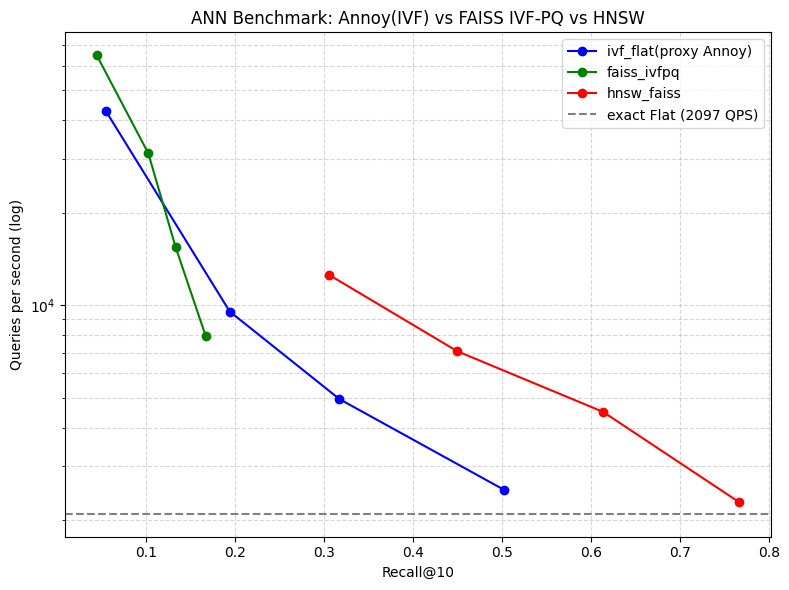

In [3]:
def recall(pred, gt):
    return float(np.mean([len(set(p) & set(g)) / K for p, g in zip(pred, gt)]))


flat = faiss.IndexFlatL2(D)
flat.add(xb)
_, gt = flat.search(xq, K)

rows = []

ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(D), D, 100, faiss.METRIC_L2)
ivf.train(xb)
ivf.add(xb)
for nprobe in [1, 5, 10, 20]:
    ivf.nprobe = nprobe
    t0 = time.perf_counter()
    _, I = ivf.search(xq, K)
    qps = NQ / (time.perf_counter() - t0)
    rows.append(["ivf_flat(proxy Annoy)", nprobe, recall(I, gt), qps])
    print(f"IVF-Flat nprobe={nprobe:3d} | recall={rows[-1][2]:.3f} | {qps:8.0f} QPS")

ivfpq = faiss.IndexIVFPQ(faiss.IndexFlatL2(D), D, 100, 16, 8)
ivfpq.train(xb)
ivfpq.add(xb)
for nprobe in [1, 5, 10, 20]:
    ivfpq.nprobe = nprobe
    t0 = time.perf_counter()
    _, I = ivfpq.search(xq, K)
    qps = NQ / (time.perf_counter() - t0)
    rows.append(["faiss_ivfpq", nprobe, recall(I, gt), qps])
    print(f"IVF-PQ  nprobe={nprobe:3d} | recall={rows[-1][2]:.3f} | {qps:8.0f} QPS")

hnsw = faiss.IndexHNSWFlat(D, 16)
hnsw.hnsw.efConstruction = 200
hnsw.add(xb)
for ef in [50, 100, 200, 400]:
    hnsw.hnsw.efSearch = ef
    t0 = time.perf_counter()
    _, I = hnsw.search(xq, K)
    qps = NQ / (time.perf_counter() - t0)
    rows.append(["hnsw_faiss", ef, recall(I, gt), qps])
    print(f"HNSW    efSearch={ef:4d} | recall={rows[-1][2]:.3f} | {qps:8.0f} QPS")

t0 = time.perf_counter()
flat.search(xq, K)
qps_flat = NQ / (time.perf_counter() - t0)
print(f"Exact Flat          | recall=1.000 | {qps_flat:8.0f} QPS")

with open(OUT / "recall_qps.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metode", "parameter", "recall@10", "qps"])
    w.writerows(rows)
    w.writerow(["exact_flat", "-", 1.0, qps_flat])

fig, ax = plt.subplots(figsize=(8, 6))
for label, color in [("ivf_flat(proxy Annoy)", "blue"), ("faiss_ivfpq", "green"), ("hnsw_faiss", "red")]:
    pts = [(r[2], r[3]) for r in rows if r[0] == label]
    ax.plot(*zip(*pts), marker="o", label=label, color=color)
    for rec, qps in pts:
        ax.annotate("", (rec, qps))
ax.axhline(qps_flat, ls="--", c="gray", label=f"exact Flat ({qps_flat:.0f} QPS)")
ax.set_xlabel("Recall@10")
ax.set_ylabel("Queries per second (log)")
ax.set_yscale("log")
ax.set_title("ANN Benchmark: Annoy(IVF) vs FAISS IVF-PQ vs HNSW")
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "p5_recall_vs_qps.png", dpi=120)